<a href="https://colab.research.google.com/github/jpandersen61/SQLLiteNotebooks/blob/main/Database_Notebook_Project_economy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Database Notebook Håndværks Projektøkonomi

###ER-Diagram

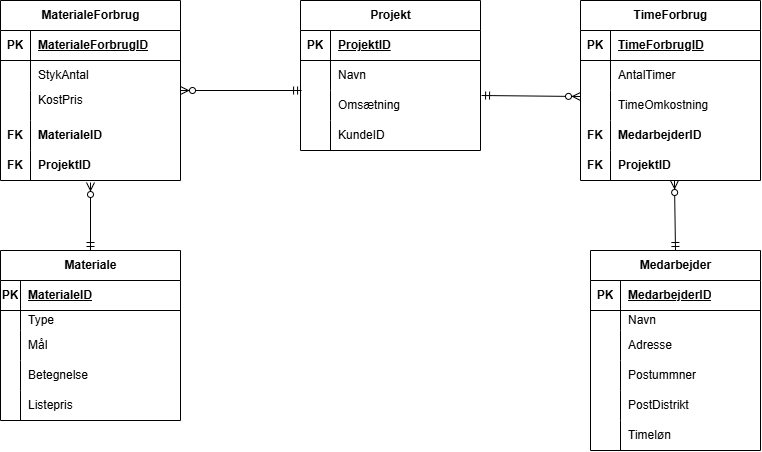

###Importing needed modules

In [1]:
import pandas as pd
import sqlite3

###Connecting to the database

I denne notebook benyttes [SQLite](https://sqlite.org/) databasen, der som det antydes er 'light', men som alligevel er OK til vores formål her, hvilket er at demonstrere, hvordan en database oprettes med SQL.

In [2]:

##Avoiding the 'database locked' error:

##Close the 'cursor' if present before proceeding
if 'SQLiteCursor' in globals():
    SQLiteCursor.close()

##Close the database connection if present before proceeding
if 'SQLiteConnetion' in globals():
    SQLiteConnetion.close()

In [3]:
#Get connection to the sales system data - initially get an empty one
SQLiteConnetion = sqlite3.connect('mydatabase.db')

In [4]:
# create cursor object
SQLiteCursor = SQLiteConnetion.cursor()

###Drop eksisterende tabeller

Nedenstående SQL script bliver udført for at "rydde" databasen

In [5]:
SQLDropTableScript = """
DROP TABLE IF EXISTS Medarbejder;
DROP TABLE IF EXISTS Materiale;
DROP TABLE IF EXISTS Projekt;
DROP TABLE IF EXISTS FakturaLinie;
DROP TABLE IF EXISTS Table5;
DROP TABLE IF EXISTS Table6;
"""

In [6]:
SQLiteCursor.executescript(SQLDropTableScript)

###Etabler 1. tabel

In [7]:
#Define CREATE TABLE statement for table1
SQLCreateTable1 = """
CREATE TABLE Medarbejder(
    MedarbejderID int NOT NULL PRIMARY KEY,
    Navn VARCHAR(30) NOT NULL,
    Adresse VARCHAR(50),
    Postnummer VARCHAR(4),
    PostDistrikt VARCHAR(30),
    TimeLøn FLOAT NOT NULL
)
"""


In [8]:
#Run CREATE TABLE statement in SQLite
SQLiteCursor.execute(SQLCreateTable1)

In [9]:
#Define INSERT INTO statement for table1
SQLInsertIntoTable1 = """
INSERT INTO Medarbejder (MedarbejderID, Navn, Adresse, Postnummer, PostDistrikt,TimeLøn)
VALUES
(1,'Jens Pedersen','Maglevej 42C', '4700', 'Næstved',300),
(2,'Anders Andersen', 'Lillevej 13', '4700', 'Næstved',400),
(3,'Hans Olsen', 'Mellemvej 34B', '4000', 'Roskilde',350),
(4,'Anna Lise Hansen', 'Maglelillevej 99', '4000', 'Roskilde',325)
"""


In [10]:
#Run INSERT INTO statement in SQLite
SQLiteCursor.execute(SQLInsertIntoTable1)

In [11]:
#Define SELECT...FROM statement for extracting all data from table 1
Query1 = """
SELECT * FROM Medarbejder
"""

In [12]:
#Get DataFrame with table 1 data by applying the SELECT...FROM statement on the SQLiteConnetion
QueryResult1 = pd.read_sql(Query1, SQLiteConnetion)

#Replace empty values with blank
QueryResult1=QueryResult1.fillna('')

#Display DataFrame
QueryResult1

,MedarbejderID,Navn,Adresse,Postnummer,PostDistrikt,TimeLøn
0,1,Jens Pedersen,Maglevej 42C,4700,Næstved,300.0
1,2,Anders Andersen,Lillevej 13,4700,Næstved,400.0
2,3,Hans Olsen,Mellemvej 34B,4000,Roskilde,350.0
3,4,Anna Lise Hansen,Maglelillevej 99,4000,Roskilde,325.0


### Etabler 2. tabel

In [13]:
#Define CREATE TABLE statement for table 2
SQLCreateTable2 = """
CREATE TABLE Materiale(
       MaterialeID INTEGER PRIMARY KEY NOT NULL,
       Type VARCHAR(30) NOT NULL,
       Betegnelse VARCHAR(30) NOT NULL,
       Mål VARCHAR(20) NOT NULL,
       Listepris FLOAT
       )
       """

In [14]:
#Run CREATE TABLE statement in SQLite
SQLiteCursor.execute(SQLCreateTable2)

In [15]:
#Define INSERT INTO statement for table 2
SQLInsertIntoTable2 = """
INSERT INTO Materiale (MaterialeID, Type, Betegnelse, Mål, Listepris)
VALUES
    ( 1,	'Cement',                  '25 kg',	      'Sæk',	  89),
    ( 2,	'Rapid cement',            '25 kg',	      'Sæk',	 109),
    ( 3,	'Mursten',                 'røde',	      'Stk',	   5.95),
    ( 4,	'Mursten',                 'gule',	      'Stk',	   8.00),
    ( 5,	'Gipsplade',               'standard',    'Stk',	  61.51),
    ( 6,	'Fibergipsplade',          '',  	        'Stk',	 170),
    ( 7,	'OSB-plade',               '11 mm',	      'Stk',	 149.95),
    ( 8,	'OSB-plade',               '15 mm',	      'Stk',	 209.95),
    ( 9,	'OSB-plade',               '18 mm',	      'Stk',	 239.95),
    (10,	'OSB-plade',               '18 mm TG2',   'Stk',	 330),
    (11,	'MDF-plade',               '12 mm',	      'Stk',	 299),
    (12,	'Krydsfiner',              '6 mm',	      'Stk',	 329),
    (13,	'Reglar',                  '45 × 95 mm',  'Meter',	17.50),
    (14,	'Trykimprægnerede reglar', '',	          'Meter',	21.95),
    (15,	'Forskallingsbrædder',	   '',            'Meter',	 9.95),
    (16,	'Trælægter',               '38 × 57 mm',  'Meter',	 9.95),
    (17,	'Spærtræ',                 '45 × 120 mm', 'Meter',	28.95),
    (18,	'Spærtræ',                 '45 × 145 mm',	'Meter',	33.95),
    (19,	'Spærtræ',                 '45 × 195 mm',	'Meter',	43.95),
    (20,	'Mineraluld',              '70 mm',	      'm²',	    37),
    (21,	'Gipsplade',               'renovering',	'Stk',	  95),
    (22,	'Varmvægsplade',           '45 mm',	      'Stk',	 645),
    (23,	'Tagpap',                  '1 × 5 meter',	'Rulle', 449),
    (24,	'Terrassebrædder',         '',	          'Meter',	14),
    (25,	'Terrasseskruer',          'A2',	        'Pakke',	79.95),
    (26,	'Firkantsøm',              '',	          'Pakke',	49.95),
    (27,	'Standard gipsplade',      '',	          'm²',	    28),
    (28,	'Krydsfiner',              '12 mm',	      'Plade', 586.40),
    (29,	'Trykimprægneret stolpe',  '97 × 97 mm',	'Stk',	 237.33),
    (30,	'Høvlet forskalling',      '22 × 100 mm',	'Stk',	  69.93)
    """

In [16]:
#Run INSERT INTO statement in SQLite
SQLiteCursor.execute(SQLInsertIntoTable2)

In [17]:
#Define SELECT...FROM statement for extracting all data from table 2
Query2 = """
SELECT * FROM Materiale
"""

In [18]:
#Get DataFrame with table 3 data by applying the SELECT...FROM statement on the SQLiteConnetion
QueryResult2 = pd.read_sql(Query2, SQLiteConnetion)

#Replace empty values with blank
QueryResult2=QueryResult2.fillna('')

#Display DataFrame
QueryResult2

,MaterialeID,Type,Betegnelse,Mål,Listepris
0,1,Cement,25 kg,Sæk,89.00
1,2,Rapid cement,25 kg,Sæk,109.00
2,3,Mursten,røde,Stk,5.95
3,4,Mursten,gule,Stk,8.00
4,5,Gipsplade,standard,Stk,61.51
5,6,Fibergipsplade,,Stk,170.00
6,7,OSB-plade,11 mm,Stk,149.95
7,8,OSB-plade,15 mm,Stk,209.95
8,9,OSB-plade,18 mm,Stk,239.95
9,10,OSB-plade,18 mm TG2,Stk,330.00


### Etabler 3. tabel

In [19]:
#Define CREATE TABLE statement for table 3
SQLCreateTable3 = """
CREATE TABLE Projekt(
       ProjektID INTEGER PRIMARY KEY  NOT NULL,
       Navn VARCHAR(30) NOT NULL,
       Omsætning FLOAT NOT NULL,
       KundeID INTEGER)
       """

In [20]:
#Run CREATE TABLE statement in SQLite
SQLiteCursor.execute(SQLCreateTable3)

In [21]:
#Define INSERT INTO statement for table 3
SQLInsertIntoTable3 = """
INSERT INTO Projekt (ProjektID, Navn, Omsætning, KundeID)
VALUES
    (1, "Klubhus Local FC", 2000000, 20),
    (2, "Væksthuset Gro", 1400000, 29),
    (3, "Fashion Shop Butterfly", 1100000,  55)
"""

In [22]:
#Run INSERT INTO statement in SQLite
SQLiteCursor.execute(SQLInsertIntoTable3)

In [23]:
#Define SELECT...FROM statement for extracting all data from table 3
Query3 = """
SELECT * FROM Projekt
"""

In [24]:
#Get DataFrame with table 3 data by applying the SELECT...FROM statement on the SQLiteConnetion
QueryResult3 = pd.read_sql(Query3, SQLiteConnetion)

#Replace empty values with blank
QueryResult3=QueryResult3.fillna('')

#Display DataFrame
QueryResult3

,ProjektID,Navn,Omsætning,KundeID
0,1,Klubhus Local FC,2000000.0,20
1,2,Væksthuset Gro,1400000.0,29
2,3,Fashion Shop Butterfly,1100000.0,55


###Etabler 4. tabel

In [25]:
#Define CREATE TABLE statement for table 4
SQLCreateTable4 = """
CREATE TABLE MaterialeForbrug(
       MaterialeForbrugID INTEGER PRIMARY KEY  NOT NULL,
       StykAntal INTEGER NOT NULL,
       KostPris Float NOT NULL,
       ProjektID INTEGER NOT NULL,
       MaterialeID INTEGER NOT NULL,
       FOREIGN KEY (ProjektID) REFERENCES Projekt(ProjektID),
       FOREIGN KEY (MaterialeID) REFERENCES Materiale(MaterialeID)
       )
       """

In [26]:
#Run CREATE TABLE statement in SQLite
SQLiteCursor.execute(SQLCreateTable4)

In [27]:
#Define INSERT INTO statement for table 4
SQLInsertIntoTable4 = """
INSERT INTO MaterialeForbrug (MaterialeForbrugID, StykAntal, KostPris, ProjektID, MaterialeID)
VALUES
    (1, 40,  89.00,  1, 1),  -- 40 Sække Cement til Klubhus Local FC
    (2, 20, 109.00,  1, 2),  -- 20 Sække Rapid cement til Klubhus Local FC
    (3, 50,  17.50,  2, 13), -- 50 meter Reglar til Væksthuset Gro
    (4, 30,  61.51,  3, 5),  -- 30 Gipsplader til Fashion Shop Butterfly
    (5, 10, 149.95,  3, 7)   -- 10 OSB-plader til Fashion Shop Butterfly
"""

In [28]:
#Run CREATE TABLE statement in SQLite
SQLiteCursor.execute(SQLInsertIntoTable4)

In [29]:
#Define SELECT...FROM statement for extracting all data from table 4
Query4 = """
SELECT * FROM MaterialeForbrug
"""

In [30]:
#Get DataFrame with FakturaLinie data by applying the SELECT...FROM statement on the SQLiteConnetion
QueryResult4 = pd.read_sql(Query4, SQLiteConnetion)

#Replace empty values with blank
QueryResult4=QueryResult4.fillna('')

#Display DataFrame
QueryResult4

,MaterialeForbrugID,StykAntal,KostPris,ProjektID,MaterialeID
0,1,40,89.00,1,1
1,2,20,109.00,1,2
2,3,50,17.50,2,13
3,4,30,61.51,3,5
4,5,10,149.95,3,7


### Etabler 5. tabel

In [31]:
#Define CREATE TABLE statement for table 5
SQLCreateTable5 = """
CREATE TABLE TimeForbrug(
       TimeForbrugID INTEGER PRIMARY KEY NULL,
       AntalTimer INTEGER NOT NULL,
       TimeOmkostning FLOAT NOT NULL,
       ProjektID INTEGER NOT NULL,
       MedarbejderID INTEGER NOT NULL,
       FOREIGN KEY (ProjektID) REFERENCES Projekt(ProjektID),
       FOREIGN KEY (MedarbejderID) REFERENCES Medarbejder(MedarbejderID)
       )
       """

In [32]:
#Run CREATE TABLE statement in SQLite
SQLiteCursor.execute(SQLCreateTable5)

In [33]:
#Define INSERT INTO statement for table 5
SQLInsertIntoTable5 = """
INSERT INTO TimeForbrug(TimeForbrugID, AntalTimer, TimeOmkostning, ProjektID, MedarbejderID)
VALUES
    (1, 10, 300.00, 1, 1), -- Jens Pedersen arbejder 10 timer på Klubhus Local FC
    (2,  8, 400.00, 1, 2), -- Anders Andersen arbejder 8 timer på Klubhus Local FC
    (3, 15, 350.00, 2, 3), -- Hans Olsen arbejder 15 timer på Væksthuset Gro
    (4, 12, 325.00, 3, 4), -- Anna Lise Hansen arbejder 12 timer på Fashion Shop Butterfly
    (5,  5, 300.00, 3, 1)  -- Jens Pedersen arbejder 5 timer på Fashion Shop Butterfly
"""

In [34]:
#Run CREATE TABLE statement in SQLite
SQLiteCursor.execute(SQLInsertIntoTable5)

In [35]:
#Define SELECT...FROM statement for extracting all data from table 5
Query5 = """
SELECT * FROM TimeForbrug
"""

In [36]:
#Get DataFrame with table 5 data by applying the SELECT...FROM statement on the SQLiteConnetion
QueryResult5 = pd.read_sql(Query5, SQLiteConnetion)

#Replace empty values with blank
QueryResult5=QueryResult5.fillna('')

#Display DataFrame
QueryResult5

,TimeForbrugID,AntalTimer,TimeOmkostning,ProjektID,MedarbejderID
0,1,10,300.0,1,1
1,2,8,400.0,1,2
2,3,15,350.0,2,3
3,4,12,325.0,3,4
4,5,5,300.0,3,1


### Etabler 6. tabel

In [37]:
#Define CREATE TABLE statement for table 6
SQLCreateTable6 = """
CREATE TABLE Table6(
       Table5Id INTEGER PRIMARY KEY AUTOINCREMENT NOT NULL,
       EtFelt VARCHAR(30) NOT NULL,
       AndetFelt VARCHAR(40) NOT NULL,
       TredjeFelt Float NOT NULL,
       FjerdeFelt int NOT NULL
       )
       """

In [38]:
#Run CREATE TABLE statement in SQLite
SQLiteCursor.execute(SQLCreateTable6)

In [39]:
#Define INSERT INTO statement for table 6
SQLInsertIntoTable6 = """
INSERT INTO Table6 (EtFelt,AndetFelt,TredjeFelt,FjerdeFelt)
VALUES
    ("", "", 0, 0),
    ("", "", 0, 0),
    ("", "", 0, 0),
    ("", "", 0, 0),
    ("", "", 0, 0)
"""

In [40]:
#Run CREATE TABLE statement in SQLite
SQLiteCursor.execute(SQLInsertIntoTable6)

In [41]:
#Define SELECT...FROM statement for extracting all data from table 6
Query6 = """
SELECT * FROM Table6
"""

In [42]:
#Get DataFrame with table 6 data by applying the SELECT...FROM statement on the SQLiteConnetion
QueryResult6 = pd.read_sql(Query6, SQLiteConnetion)

#Replace empty values with blank
QueryResult6=QueryResult6.fillna('')

#Display DataFrame
QueryResult6

,Table5Id,EtFelt,AndetFelt,TredjeFelt,FjerdeFelt
0,1,,,0.0,0
1,2,,,0.0,0
2,3,,,0.0,0
3,4,,,0.0,0
4,5,,,0.0,0


# Ekstra udtræk

### Definer 1. ekstra udtræk

In [43]:
#Define SELECT...FROM statement
ExtraQuery1 = """
SELECT 	Navn,	Omsætning, SUM(AntalTimer * TimeForbrug.TimeOmkostning) AS TotalTimeOmkostning FROM Projekt
JOIN TimeForbrug ON Projekt.ProjektID = TimeForbrug.ProjektID
GROUP BY Projekt.ProjektID
"""

Hent data fra database og læg dem i en DataFrame

In [44]:
ExtraQueryResult1=None;
if len(ExtraQuery1) > 1:
   #Get DataFrame with extra query 1 data by applying the SELECT...FROM statement on the SQLiteConnetion
   ExtraQueryResult1 = pd.read_sql(ExtraQuery1, SQLiteConnetion)

   #Replace empty values with blank
   ExtraQueryResult1=ExtraQueryResult1.fillna('')

#Display DataFrame
ExtraQueryResult1

,Navn,Omsætning,TotalTimeOmkostning
0,Klubhus Local FC,2000000.0,6200.0
1,Væksthuset Gro,1400000.0,5250.0
2,Fashion Shop Butterfly,1100000.0,5400.0


### Definer 2. ekstra udtræk

In [45]:
#Define SELECT...FROM statement
ExtraQuery2 = """
"""

In [46]:
ExtraQueryResult2=None
if len(ExtraQuery2) > 1:
   #Get DataFrame with extra query 2 data by applying the SELECT...FROM statement on the SQLiteConnetion
   ExtraQueryResult2 = pd.read_sql(ExtraQuery2, SQLiteConnetion)

   #Replace empty values with blank
   ExtraQueryResult2=ExtraQueryResult2.fillna('')

#Display DataFrame
ExtraQueryResult2

### Definer 3. ekstra udtræk

In [47]:
#Define SELECT...FROM statement
ExtraQuery3 = """
"""

In [48]:
ExtraQueryResult3=None
if len(ExtraQuery3) > 1:
   #Get DataFrame with extra query 3 data by applying the SELECT...FROM statement on the SQLiteConnetion
   ExtraQueryResult3 = pd.read_sql(ExtraQuery3, SQLiteConnetion)

   #Replace empty values with blank
   ExtraQueryResult3=ExtraQueryResult3.fillna('')

#Display DataFrame
ExtraQueryResult3

### Export til Excel:

In [50]:
#Mounting to your Google drive
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [51]:
#Setting the file location for the Excel file
ExcelFilePath = "drive/My Drive/Colab Notebooks/Queries.xlsx"

In [52]:
#Direct queries to Excel sheets
ExcelSheets = [
    {'dataFrame' : QueryResult1, 'sheet_name' : 'Query1'},
    {'dataFrame' : QueryResult2, 'sheet_name' : 'Query2'},
    {'dataFrame' : QueryResult3, 'sheet_name' : 'Query3'},
    {'dataFrame' : QueryResult4, 'sheet_name' : 'Query4'},
    {'dataFrame' : QueryResult5, 'sheet_name' : 'Query5'},
    {'dataFrame' : QueryResult6, 'sheet_name' : 'Query6'},
    {'dataFrame' : ExtraQueryResult1, 'sheet_name' : 'ExtraQuery1'},
    {'dataFrame' : ExtraQueryResult2, 'sheet_name' : 'ExtraQuery2'},
    {'dataFrame' : ExtraQueryResult3, 'sheet_name' : 'ExtraQuery3'}
    ]

In [53]:
#Do the actual write to the Excel file:
import pandas as pd
with pd.ExcelWriter(ExcelFilePath, mode='w') as writer:
     for sheet in ExcelSheets:
      if isinstance(sheet['dataFrame'], pd.DataFrame):
       sheet['dataFrame'].to_excel(writer, sheet_name=sheet['sheet_name'])